In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

PAPERS_FILE = PROJECT_ROOT / "data" / "raw" / "papers.jsonl"
CONNECTED_FILE = PROJECT_ROOT / "data" / "raw" / "connected_papers.jsonl"
CITATIONS_FILE = PROJECT_ROOT / "data" / "raw" / "citations.csv"
FAILED_FILE = PROJECT_ROOT / "data" / "raw" / "failed_paper_ids.txt"

print("Project root:", PROJECT_ROOT)

print("\nFiles:")
print("papers.jsonl:", PAPERS_FILE.exists())
print("connected_papers.jsonl:", CONNECTED_FILE.exists())
print("citations.csv:", CITATIONS_FILE.exists())
print("failed_paper_ids.txt:", FAILED_FILE.exists())

Project root: c:\Users\Shubham\OneDrive\Desktop\MajorProject

Files:
papers.jsonl: True
connected_papers.jsonl: True
citations.csv: True
failed_paper_ids.txt: True


In [2]:
def load_jsonl(path):
    records = []

    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()

            if not line:
                continue

            try:
                records.append(json.loads(line))
            except json.JSONDecodeError:
                pass

    return pd.DataFrame(records)


original_df = load_jsonl(PAPERS_FILE)
connected_df = load_jsonl(CONNECTED_FILE)

print("Original papers:", len(original_df))
print("Connected papers:", len(connected_df))

Original papers: 5000
Connected papers: 89473


In [3]:
papers_df = pd.concat(
    [original_df, connected_df],
    ignore_index=True
)

print("Total paper records:", len(papers_df))

Total paper records: 94473


In [4]:
duplicate_count = papers_df["paperId"].duplicated().sum()

unique_paper_ids = papers_df["paperId"].nunique()

print("Total records:", len(papers_df))
print("Unique paper IDs:", unique_paper_ids)
print("Duplicate records:", duplicate_count)

Total records: 94473
Unique paper IDs: 94471
Duplicate records: 2


In [5]:
metadata_columns = [
    "paperId",
    "title",
    "abstract",
    "authors",
    "year",
    "venue",
    "citationCount",
    "fieldsOfStudy",
    "publicationDate",
    "openAccessPdf"
]

missing = papers_df[metadata_columns].isna().sum()

missing_percent = (
    missing / len(papers_df) * 100
).round(2)

metadata_report = pd.DataFrame({
    "Missing": missing,
    "Missing %": missing_percent
})

metadata_report

,Missing,Missing %
paperId,0,0.00
title,0,0.00
abstract,38037,40.26
authors,0,0.00
year,447,0.47
venue,0,0.00
citationCount,0,0.00
fieldsOfStudy,10054,10.64
publicationDate,10422,11.03
openAccessPdf,0,0.00


In [6]:
def is_empty(value):
    return (
        pd.isna(value)
        or str(value).strip() == ""
    )


empty_title = papers_df["title"].apply(is_empty).sum()
empty_abstract = papers_df["abstract"].apply(is_empty).sum()

print("Empty titles:", empty_title)
print("Empty abstracts:", empty_abstract)

Empty titles: 0
Empty abstracts: 38039


In [7]:
usable_semantic = papers_df[
    (~papers_df["title"].apply(is_empty)) &
    (~papers_df["abstract"].apply(is_empty))
]

print(
    "Papers usable for SciBERT:",
    len(usable_semantic)
)

print(
    "Percentage usable:",
    round(
        len(usable_semantic) / len(papers_df) * 100,
        2
    ),
    "%"
)

Papers usable for SciBERT: 56434
Percentage usable: 59.74 %


In [8]:
citations_df = pd.read_csv(CITATIONS_FILE)

print("Citation rows:", len(citations_df))
print()

print(citations_df.head())
print()

print(citations_df.columns.tolist())

Citation rows: 103496

                               source_paper  \
0  00000c33779acab142af6c7a6dae8b36fac0805d   
1  00000c33779acab142af6c7a6dae8b36fac0805d   
2  00000c33779acab142af6c7a6dae8b36fac0805d   
3  00000c33779acab142af6c7a6dae8b36fac0805d   
4  00000c33779acab142af6c7a6dae8b36fac0805d   

                               target_paper relationship  
0  9357a46f47c6f2bea9761cbcd79ddab4e350d557    reference  
1  c59c06c8a44acbda74667e76459b2df8dae90273    reference  
2  286519b404064fe4e52f1dc5483596fe683aed03    reference  
3  49e3c326f67a5916bdb617f9399b21c16f9803ad    reference  
4  4bf43099563822c04eb58e6ac7c745680eafcbe7    reference  

['source_paper', 'target_paper', 'relationship']


In [9]:
citation_duplicates = citations_df.duplicated(
    subset=["source_paper", "target_paper"]
).sum()

print(
    "Duplicate source-target edges:",
    citation_duplicates
)

Duplicate source-target edges: 0


In [10]:
self_loops = (
    citations_df["source_paper"]
    ==
    citations_df["target_paper"]
).sum()

print("Self-loop edges:", self_loops)

Self-loop edges: 0


In [11]:
paper_ids = set(
    papers_df["paperId"].dropna()
)

source_ids = set(
    citations_df["source_paper"].dropna()
)

target_ids = set(
    citations_df["target_paper"].dropna()
)

graph_ids = source_ids | target_ids

print("Paper metadata IDs:", len(paper_ids))
print("Citation source IDs:", len(source_ids))
print("Citation target IDs:", len(target_ids))
print("Unique citation IDs:", len(graph_ids))

Paper metadata IDs: 94471
Citation source IDs: 3291
Citation target IDs: 88884
Unique citation IDs: 92088


In [12]:
missing_metadata_ids = graph_ids - paper_ids

print(
    "Citation IDs without metadata:",
    len(missing_metadata_ids)
)

Citation IDs without metadata: 7


In [13]:
coverage = (
    len(graph_ids & paper_ids)
    / len(graph_ids)
    * 100
)

print(
    f"Graph metadata coverage: {coverage:.2f}%"
)

Graph metadata coverage: 99.99%


In [14]:
usable_edges = citations_df[
    citations_df["source_paper"].isin(paper_ids)
    &
    citations_df["target_paper"].isin(paper_ids)
].copy()

print(
    "Total citation edges:",
    len(citations_df)
)

print(
    "Edges with both endpoints having metadata:",
    len(usable_edges)
)

print(
    "Usable edge percentage:",
    round(
        len(usable_edges) / len(citations_df) * 100,
        2
    ),
    "%"
)

Total citation edges: 103496
Edges with both endpoints having metadata: 103482
Usable edge percentage: 99.99 %


In [15]:
G = nx.Graph()

# Add all papers as nodes
G.add_nodes_from(paper_ids)

# Remove self-loops
usable_edges = usable_edges[
    usable_edges["source_paper"]
    !=
    usable_edges["target_paper"]
]

# Remove duplicate edges
usable_edges = usable_edges.drop_duplicates(
    subset=["source_paper", "target_paper"]
)

# Add edges
G.add_edges_from(
    zip(
        usable_edges["source_paper"],
        usable_edges["target_paper"]
    )
)

print("Graph nodes:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())

Graph nodes: 94471
Graph edges: 103482


In [16]:
components = list(
    nx.connected_components(G)
)

component_sizes = sorted(
    [len(c) for c in components],
    reverse=True
)

print(
    "Connected components:",
    len(component_sizes)
)

print(
    "Largest component:",
    component_sizes[0]
)

print(
    "Top 10 component sizes:"
)

print(component_sizes[:10])



Connected components: 2709
Largest component: 86396
Top 10 component sizes:
[86396, 119, 110, 95, 92, 80, 78, 72, 66, 64]


In [17]:
isolated_nodes = list(
    nx.isolates(G)
)

print(
    "Isolated nodes:",
    len(isolated_nodes)
)

print(
    "Isolated percentage:",
    round(
        len(isolated_nodes)
        / G.number_of_nodes()
        * 100,
        2
    ),
    "%"
)

Isolated nodes: 2390
Isolated percentage: 2.53 %


In [18]:
# Calculate degree for every node
degrees = np.array([
    degree
    for _, degree in G.degree()
])

print("Number of nodes:", len(degrees))
print("Minimum degree:", degrees.min())
print("Maximum degree:", degrees.max())
print("Mean degree:", degrees.mean())
print("Median degree:", np.median(degrees))
print("90th percentile:", np.percentile(degrees, 90))
print("99th percentile:", np.percentile(degrees, 99))

Number of nodes: 94471
Minimum degree: 0
Maximum degree: 383
Mean degree: 2.1907675371277957
Median degree: 1.0
90th percentile: 1.0
99th percentile: 42.0


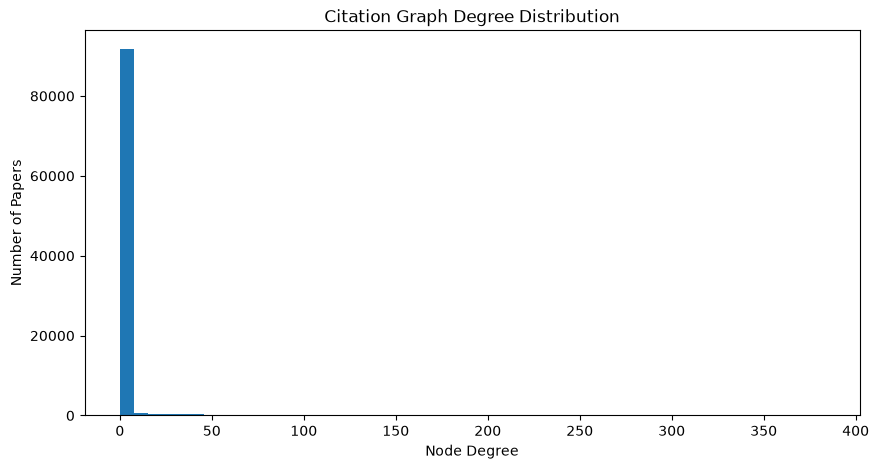

In [19]:
plt.figure(figsize=(10, 5))

plt.hist(
    degrees,
    bins=50
)

plt.xlabel("Node Degree")
plt.ylabel("Number of Papers")
plt.title("Citation Graph Degree Distribution")

plt.show()

In [20]:
degree_df = pd.DataFrame(
    G.degree(),
    columns=["paperId", "degree"]
)

degree_df = degree_df.sort_values(
    "degree",
    ascending=False
)

top_degree = degree_df.head(20).merge(
    papers_df[
        ["paperId", "title", "year"]
    ],
    on="paperId",
    how="left"
)

top_degree

,paperId,degree,title,year
0,013edcfc3237609f94157588f2849bfae00ad28c,383,Advancements in characterization of protein dy...,2026.0
1,00c941f2f6b1e5180a6ad2823046e30241de6113,371,A Comprehensive Survey of Machine Learning Bas...,2020.0
2,00044a527a0642b08f385cda845331f0fc8cbbfd,368,At the Confluence of Artificial Intelligence a...,2023.0
3,0084f3cb0a1754272151c5268a783f24bf5676a0,351,"Review of deep learning: concepts, CNN archite...",2021.0
4,00f08c81cf7a969766cc2956f037f8a6a781950f,341,Vision + X: A Survey on Multimodal Learning in...,2022.0
5,0033fabb9f9dad4bdaa81470593601d9506d2812,326,Tensor Networks for Dimensionality Reduction a...,2016.0
6,00a36102c009698878c4285f66f84e827efc4803,312,Proactive and reactive engagement of artificia...,2023.0
7,01726d8db601b4c09a1ee306a98f7b1d99e7b12c,312,A review of uncertainty quantification in medi...,2024.0
8,00c4e1abbc489cfeee9e3ec55fa23ad8e9fd06db,307,A Survey on Learnable Evolutionary Algorithms ...,2022.0
9,00f3a400d5433bdd1f1ddcfbedc298b44e7167c0,293,A Survey of Embodied Learning for Object-centr...,2024.0


In [21]:
print("=" * 70)
print("FINAL DATASET VALIDATION")
print("=" * 70)

print(f"Paper records:                 {len(papers_df):,}")
print(f"Unique paper IDs:              {papers_df['paperId'].nunique():,}")
print(f"Duplicate paper records:       {duplicate_count:,}")

print()

print(f"Total citation rows:           {len(citations_df):,}")
print(f"Unique citation IDs:           {len(graph_ids):,}")
print(f"Usable citation edges:         {len(usable_edges):,}")

print()

print(f"Empty titles:                  {empty_title:,}")
print(f"Empty abstracts:               {empty_abstract:,}")
print(f"SciBERT-usable papers:         {len(usable_semantic):,}")

print()

print(f"Graph nodes:                   {G.number_of_nodes():,}")
print(f"Graph edges:                   {G.number_of_edges():,}")
print(f"Connected components:          {len(components):,}")
print(f"Isolated nodes:                {len(isolated_nodes):,}")

print()

print(f"Graph metadata coverage:       {coverage:.2f}%")

print("=" * 70)

FINAL DATASET VALIDATION
Paper records:                 94,473
Unique paper IDs:              94,471
Duplicate paper records:       2

Total citation rows:           103,496
Unique citation IDs:           92,088
Usable citation edges:         103,482

Empty titles:                  0
Empty abstracts:               38,039
SciBERT-usable papers:         56,434

Graph nodes:                   94,471
Graph edges:                   103,482
Connected components:          2,709
Isolated nodes:                2,390

Graph metadata coverage:       99.99%


In [22]:
metadata_only_ids = paper_ids - graph_ids

print(
    "Metadata papers not appearing in citation graph:",
    len(metadata_only_ids)
)

Metadata papers not appearing in citation graph: 2390


In [23]:
print(
    "Citation IDs with metadata:",
    len(graph_ids & paper_ids)
)

print(
    "Citation IDs without metadata:",
    len(graph_ids - paper_ids)
)

print(
    "Metadata-only papers:",
    len(paper_ids - graph_ids)
)

Citation IDs with metadata: 92081
Citation IDs without metadata: 7
Metadata-only papers: 2390


In [24]:
print("=" * 60)
print("GRAPH COVERAGE BREAKDOWN")
print("=" * 60)

print(f"Total metadata papers:       {len(paper_ids):,}")
print(f"Total citation IDs:          {len(graph_ids):,}")
print(f"Both metadata + citation:    {len(paper_ids & graph_ids):,}")
print(f"Metadata only:                {len(paper_ids - graph_ids):,}")
print(f"Citation only:                {len(graph_ids - paper_ids):,}")

GRAPH COVERAGE BREAKDOWN
Total metadata papers:       94,471
Total citation IDs:          92,088
Both metadata + citation:    92,081
Metadata only:                2,390
Citation only:                7


In [25]:
duplicate_papers = papers_df[
    papers_df["paperId"].duplicated(keep=False)
].sort_values("paperId")

duplicate_papers[
    ["paperId", "title", "year"]
]

,paperId,title,year
22062,5ed2e25fb65cbaea6ec89bd2430bf23c1cada907,Expert Systems With Applications,2025.0
42302,5ed2e25fb65cbaea6ec89bd2430bf23c1cada907,Expert Systems With Applications,2025.0
37404,9de3170740f02adcb72539cfced45c2970223803,Artificial intelligence in medicine,1989.0
62952,9de3170740f02adcb72539cfced45c2970223803,Artificial intelligence in medicine,1989.0


In [26]:
print(
    "Duplicate paper IDs:",
    duplicate_papers["paperId"].unique()
)

Duplicate paper IDs: <StringArray>
['5ed2e25fb65cbaea6ec89bd2430bf23c1cada907', '9de3170740f02adcb72539cfced45c2970223803']
Length: 2, dtype: str


In [27]:
for paper_id in duplicate_papers["paperId"].unique():

    rows = papers_df[
        papers_df["paperId"] == paper_id
    ]

    print("=" * 70)
    print("Paper ID:", paper_id)

    for col in papers_df.columns:

        values = rows[col].tolist()

        if len(set(map(str, values))) > 1:
            print(f"\nDifferent column: {col}")
            print(values)

Paper ID: 5ed2e25fb65cbaea6ec89bd2430bf23c1cada907
Paper ID: 9de3170740f02adcb72539cfced45c2970223803


In [28]:
clean_papers_df = papers_df.drop_duplicates(
    subset=["paperId"],
    keep="first"
).copy()

print("Before cleaning:", len(papers_df))
print("After cleaning:", len(clean_papers_df))
print(
    "Unique IDs:",
    clean_papers_df["paperId"].nunique()
)

Before cleaning: 94473
After cleaning: 94471
Unique IDs: 94471


In [29]:
paper_ids = set(
    clean_papers_df["paperId"].dropna()
)

print(
    "Clean paper IDs:",
    len(paper_ids)
)

Clean paper IDs: 94471


In [30]:
source_ids = set(
    citations_df["source_paper"].dropna()
)

target_ids = set(
    citations_df["target_paper"].dropna()
)

graph_ids = source_ids | target_ids

both_ids = paper_ids & graph_ids
metadata_only_ids = paper_ids - graph_ids
citation_only_ids = graph_ids - paper_ids

print("=" * 60)
print("FINAL CLEAN COVERAGE")
print("=" * 60)

print(f"Metadata papers:       {len(paper_ids):,}")
print(f"Citation IDs:          {len(graph_ids):,}")
print(f"Both:                  {len(both_ids):,}")
print(f"Metadata only:         {len(metadata_only_ids):,}")
print(f"Citation only:         {len(citation_only_ids):,}")

FINAL CLEAN COVERAGE
Metadata papers:       94,471
Citation IDs:          92,088
Both:                  92,081
Metadata only:         2,390
Citation only:         7


In [31]:
from pathlib import Path
import pandas as pd


# ============================================================
# PATHS
# ============================================================

PROJECT_ROOT = Path.cwd().parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

PAPERS_OUTPUT = PROCESSED_DIR / "papers_clean.csv"
GRAPH_NODES_OUTPUT = PROCESSED_DIR / "graph_nodes.csv"
GRAPH_EDGES_OUTPUT = PROCESSED_DIR / "graph_edges.csv"


# ============================================================
# 1. CLEAN MASTER PAPER DATASET
# ============================================================

print("=" * 70)
print("CREATING CLEAN PAPER DATASET")
print("=" * 70)

# Remove duplicate paper IDs
clean_papers_df = papers_df.drop_duplicates(
    subset=["paperId"],
    keep="first"
).copy()

# Remove rows without a paper ID
clean_papers_df = clean_papers_df[
    clean_papers_df["paperId"].notna()
].copy()

# Make paper IDs strings
clean_papers_df["paperId"] = (
    clean_papers_df["paperId"]
    .astype(str)
    .str.strip()
)

# Save
clean_papers_df.to_csv(
    PAPERS_OUTPUT,
    index=False,
    encoding="utf-8"
)

print(
    f"Saved: {PAPERS_OUTPUT}"
)

print(
    f"Total unique papers: "
    f"{len(clean_papers_df):,}"
)


# ============================================================
# 2. GRAPH NODE DATASET
# ============================================================

print()
print("=" * 70)
print("CREATING GRAPH NODE DATASET")
print("=" * 70)

# Citation IDs
source_ids = set(
    citations_df["source_paper"]
    .dropna()
    .astype(str)
    .str.strip()
)

target_ids = set(
    citations_df["target_paper"]
    .dropna()
    .astype(str)
    .str.strip()
)

graph_ids = source_ids | target_ids

# Keep only papers for which we have metadata
graph_node_ids = graph_ids & set(
    clean_papers_df["paperId"]
)

graph_nodes_df = clean_papers_df[
    clean_papers_df["paperId"].isin(graph_node_ids)
].copy()

# Save graph nodes
graph_nodes_df.to_csv(
    GRAPH_NODES_OUTPUT,
    index=False,
    encoding="utf-8"
)

print(
    f"Graph nodes: "
    f"{len(graph_nodes_df):,}"
)

print(
    f"Saved: {GRAPH_NODES_OUTPUT}"
)


# ============================================================
# 3. GRAPH EDGE DATASET
# ============================================================

print()
print("=" * 70)
print("CREATING GRAPH EDGE DATASET")
print("=" * 70)

# Copy citations
graph_edges_df = citations_df.copy()

# Normalize IDs
graph_edges_df["source_paper"] = (
    graph_edges_df["source_paper"]
    .astype(str)
    .str.strip()
)

graph_edges_df["target_paper"] = (
    graph_edges_df["target_paper"]
    .astype(str)
    .str.strip()
)

# Keep only edges where BOTH endpoints have metadata
graph_edges_df = graph_edges_df[
    graph_edges_df["source_paper"].isin(graph_node_ids)
    &
    graph_edges_df["target_paper"].isin(graph_node_ids)
].copy()

# Remove self-loops
graph_edges_df = graph_edges_df[
    graph_edges_df["source_paper"]
    !=
    graph_edges_df["target_paper"]
].copy()

# Remove duplicate source → target edges
graph_edges_df = graph_edges_df.drop_duplicates(
    subset=[
        "source_paper",
        "target_paper"
    ],
    keep="first"
).copy()

# Save
graph_edges_df.to_csv(
    GRAPH_EDGES_OUTPUT,
    index=False,
    encoding="utf-8"
)

print(
    f"Graph edges: "
    f"{len(graph_edges_df):,}"
)

print(
    f"Saved: {GRAPH_EDGES_OUTPUT}"
)


# ============================================================
# 4. FINAL SUMMARY
# ============================================================

print()
print("=" * 70)
print("PROCESSED DATASET COMPLETE")
print("=" * 70)

print(
    f"Clean papers:       {len(clean_papers_df):,}"
)

print(
    f"Graph nodes:        {len(graph_nodes_df):,}"
)

print(
    f"Graph edges:        {len(graph_edges_df):,}"
)

print()
print("Files created:")

print(
    f"  {PAPERS_OUTPUT}"
)

print(
    f"  {GRAPH_NODES_OUTPUT}"
)

print(
    f"  {GRAPH_EDGES_OUTPUT}"
)

CREATING CLEAN PAPER DATASET
Saved: c:\Users\Shubham\OneDrive\Desktop\MajorProject\data\processed\papers_clean.csv
Total unique papers: 94,471

CREATING GRAPH NODE DATASET
Graph nodes: 92,081
Saved: c:\Users\Shubham\OneDrive\Desktop\MajorProject\data\processed\graph_nodes.csv

CREATING GRAPH EDGE DATASET
Graph edges: 103,482
Saved: c:\Users\Shubham\OneDrive\Desktop\MajorProject\data\processed\graph_edges.csv

PROCESSED DATASET COMPLETE
Clean papers:       94,471
Graph nodes:        92,081
Graph edges:        103,482

Files created:
  c:\Users\Shubham\OneDrive\Desktop\MajorProject\data\processed\papers_clean.csv
  c:\Users\Shubham\OneDrive\Desktop\MajorProject\data\processed\graph_nodes.csv
  c:\Users\Shubham\OneDrive\Desktop\MajorProject\data\processed\graph_edges.csv


In [32]:
# ============================================================
# VERIFY PROCESSED CSV STRUCTURE
# ============================================================

import pandas as pd

papers_check = pd.read_csv(PAPERS_OUTPUT)
nodes_check = pd.read_csv(GRAPH_NODES_OUTPUT)
edges_check = pd.read_csv(GRAPH_EDGES_OUTPUT)

print("=" * 70)
print("PROCESSED CSV VALIDATION")

print("=" * 70)

print("\nPAPERS CLEAN")
print("Shape:", papers_check.shape)
print("Columns:", len(papers_check.columns))
print(papers_check.columns.tolist())

print("\nGRAPH NODES")
print("Shape:", nodes_check.shape)

print("Columns:", len(nodes_check.columns))
print(nodes_check.columns.tolist())

print("\nGRAPH EDGES")
print("Shape:", edges_check.shape)
print("Columns:", len(edges_check.columns))
print(edges_check.columns.tolist())

KeyboardInterrupt: 

In [33]:
from pathlib import Path

print("papers_clean size:",
      round(PAPERS_OUTPUT.stat().st_size / (1024**2), 2), "MB")

print("graph_nodes size:",
      round(GRAPH_NODES_OUTPUT.stat().st_size / (1024**2), 2), "MB")

print("graph_edges size:",
      round(GRAPH_EDGES_OUTPUT.stat().st_size / (1024**2), 2), "MB")

papers_clean size: 154.37 MB
graph_nodes size: 149.3 MB
graph_edges size: 9.18 MB


In [34]:
import pandas as pd

# ============================================================
# MEMORY-EFFICIENT CSV VALIDATION
# ============================================================

print("=" * 70)
print("VALIDATING PROCESSED CSV FILES")
print("=" * 70)


# ------------------------------------------------------------
# 1. Check headers without loading entire files
# ------------------------------------------------------------

papers_header = pd.read_csv(
    PAPERS_OUTPUT,
    nrows=0
)

nodes_header = pd.read_csv(
    GRAPH_NODES_OUTPUT,
    nrows=0
)

edges_header = pd.read_csv(
    GRAPH_EDGES_OUTPUT,
    nrows=0
)

print("\nPAPERS COLUMNS:")
print(papers_header.columns.tolist())

print("\nGRAPH NODE COLUMNS:")
print(nodes_header.columns.tolist())

print("\nGRAPH EDGE COLUMNS:")
print(edges_header.columns.tolist())


# ------------------------------------------------------------
# 2. Count rows using chunks
# ------------------------------------------------------------

def count_csv_rows(path, chunksize=5000):

    total = 0

    for chunk in pd.read_csv(
        path,
        chunksize=chunksize,
        usecols=[0]
    ):
        total += len(chunk)

    return total


papers_count = count_csv_rows(PAPERS_OUTPUT)

nodes_count = count_csv_rows(GRAPH_NODES_OUTPUT)

edges_count = count_csv_rows(GRAPH_EDGES_OUTPUT)


print("\n" + "=" * 70)
print("ROW COUNTS")
print("=" * 70)

print(
    "papers_clean:",
    f"{papers_count:,}"
)

print(
    "graph_nodes:",
    f"{nodes_count:,}"
)

print(
    "graph_edges:",
    f"{edges_count:,}"
)

VALIDATING PROCESSED CSV FILES

PAPERS COLUMNS:
['paperId', 'title', 'abstract', 'authors', 'year', 'venue', 'citationCount', 'fieldsOfStudy', 'publicationDate', 'openAccessPdf']

GRAPH NODE COLUMNS:
['paperId', 'title', 'abstract', 'authors', 'year', 'venue', 'citationCount', 'fieldsOfStudy', 'publicationDate', 'openAccessPdf']

GRAPH EDGE COLUMNS:
['source_paper', 'target_paper', 'relationship']

ROW COUNTS
papers_clean: 94,471
graph_nodes: 92,081
graph_edges: 103,482


In [35]:
print("=" * 70)
print("SAMPLE DATA")
print("=" * 70)

sample_papers = pd.read_csv(
    PAPERS_OUTPUT,
    nrows=5,
    usecols=[
        "paperId",
        "title",
        "abstract",
        "year"
    ]
)

display(sample_papers)

SAMPLE DATA


,paperId,title,abstract,year
0,00000c33779acab142af6c7a6dae8b36fac0805d,Insights into Household Electric Vehicle Charg...,In the era of burgeoning electric vehicle (EV)...,2024.0
1,0000238f07f151172cf2602588ba762b55c8464b,Personalized prediction of response to smartph...,Meditation apps are popular and may reduce psy...,2021.0
2,0000315635be19f6278dbc72597b3065fac405f0,Abstractive text summarization of low-resource...,Background Humans must be able to cope with th...,2023.0
3,00005d68c6c7eb4d3c27da8242a30b9a498f991e,Detection of DDoS Attacks on Clouds Computing ...,The growing number of cloud-based services has...,2023.0
4,0000627a402141da113dfb8148711fecfcb4fdd1,Design of Network Intrusion Detection Model Ba...,The traditional machine learning model cannot ...,2022.0


In [36]:
sample_nodes = pd.read_csv(
    GRAPH_NODES_OUTPUT,
    nrows=5,
    usecols=[
        "paperId",
        "title",
        "year"
    ]
)

display(sample_nodes)

,paperId,title,year
0,00000c33779acab142af6c7a6dae8b36fac0805d,Insights into Household Electric Vehicle Charg...,2024.0
1,0000238f07f151172cf2602588ba762b55c8464b,Personalized prediction of response to smartph...,2021.0
2,0000315635be19f6278dbc72597b3065fac405f0,Abstractive text summarization of low-resource...,2023.0
3,00005d68c6c7eb4d3c27da8242a30b9a498f991e,Detection of DDoS Attacks on Clouds Computing ...,2023.0
4,0000627a402141da113dfb8148711fecfcb4fdd1,Design of Network Intrusion Detection Model Ba...,2022.0


In [37]:
graph_node_ids_check = set()

for chunk in pd.read_csv(
    GRAPH_NODES_OUTPUT,
    chunksize=5000,
    usecols=["paperId"]
):
    graph_node_ids_check.update(
        chunk["paperId"].dropna().astype(str)
    )

print(
    "Unique graph node IDs:",
    len(graph_node_ids_check)
)

Unique graph node IDs: 92081


In [38]:
edge_count = 0
invalid_edges = 0

for chunk in pd.read_csv(
    GRAPH_EDGES_OUTPUT,
    chunksize=5000,
    usecols=[
        "source_paper",
        "target_paper"
    ]
):

    edge_count += len(chunk)

    invalid_edges += (
        ~chunk["source_paper"].astype(str).isin(
            graph_node_ids_check
        )
    ).sum()

    invalid_edges += (
        ~chunk["target_paper"].astype(str).isin(
            graph_node_ids_check
        )
    ).sum()


print("Total edges:", edge_count)
print("Invalid endpoints:", invalid_edges)

Total edges: 103482
Invalid endpoints: 0


In [39]:
import pandas as pd
import networkx as nx
import numpy as np

# Load only the columns needed for graph analysis
nodes = pd.read_csv(
    GRAPH_NODES_OUTPUT,
    usecols=["paperId"]
)

edges = pd.read_csv(
    GRAPH_EDGES_OUTPUT,
    usecols=["source_paper", "target_paper"]
)

# Build graph
G = nx.Graph()

G.add_nodes_from(nodes["paperId"].astype(str))

G.add_edges_from(
    zip(
        edges["source_paper"].astype(str),
        edges["target_paper"].astype(str)
    )
)

# ------------------------------------------------------------
# Basic statistics
# ------------------------------------------------------------

degrees = np.array([
    degree for _, degree in G.degree()
])

print("=" * 70)
print("FINAL CITATION GRAPH STATISTICS")
print("=" * 70)

print(f"Nodes:              {G.number_of_nodes():,}")
print(f"Edges:              {G.number_of_edges():,}")
print(f"Average degree:     {degrees.mean():.2f}")
print(f"Median degree:      {np.median(degrees):.0f}")
print(f"Maximum degree:     {degrees.max():,}")

# ------------------------------------------------------------
# Isolated nodes
# ------------------------------------------------------------

isolated = list(nx.isolates(G))

print(f"Isolated nodes:     {len(isolated):,}")

# ------------------------------------------------------------
# Connected components
# ------------------------------------------------------------

components = list(nx.connected_components(G))

component_sizes = sorted(
    [len(component) for component in components],
    reverse=True
)

print(f"Components:         {len(components):,}")
print(f"Largest component:  {component_sizes[0]:,}")

print("\nTop 10 component sizes:")
print(component_sizes[:10])

# ------------------------------------------------------------
# Degree distribution
# ------------------------------------------------------------

print("\nDegree statistics:")
print(f"Degree 0:           {(degrees == 0).sum():,}")
print(f"Degree 1:           {(degrees == 1).sum():,}")
print(f"Degree 2:           {(degrees == 2).sum():,}")
print(f"Degree 3:           {(degrees == 3).sum():,}")
print(f"Degree >= 5:        {(degrees >= 5).sum():,}")
print(f"Degree >= 10:       {(degrees >= 10).sum():,}")
print(f"Degree >= 20:       {(degrees >= 20).sum():,}")

FINAL CITATION GRAPH STATISTICS
Nodes:              92,081
Edges:              103,482
Average degree:     2.25
Median degree:      1
Maximum degree:     383
Isolated nodes:     0
Components:         319
Largest component:  86,396

Top 10 component sizes:
[86396, 119, 110, 95, 92, 80, 78, 72, 66, 64]

Degree statistics:
Degree 0:           0
Degree 1:           83,134
Degree 2:           4,380
Degree 3:           977
Degree >= 5:        3,136
Degree >= 10:       2,497
Degree >= 20:       1,952


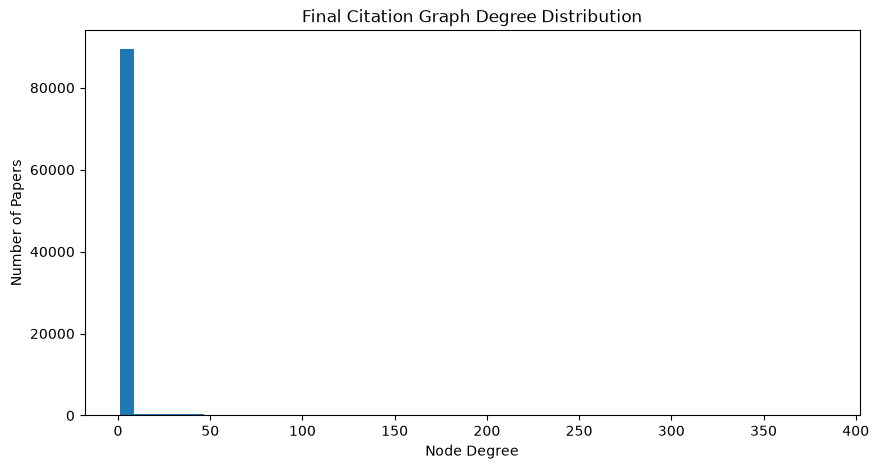

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    degrees,
    bins=50
)

plt.xlabel("Node Degree")
plt.ylabel("Number of Papers")
plt.title("Final Citation Graph Degree Distribution")

plt.show()

In [41]:
# ============================================================
# UNDERSTAND DEGREE-1 NODES
# ============================================================

degree_series = pd.Series(
    dict(G.degree()),
    name="degree"
)

print("=" * 70)
print("DEGREE BREAKDOWN")
print("=" * 70)

for threshold in [0, 1, 2, 3, 5, 10, 20, 50, 100]:

    count = (degree_series >= threshold).sum()

    percentage = (
        count / len(degree_series) * 100
    )

    print(
        f"Degree >= {threshold:<3}: "
        f"{count:>7,} "
        f"({percentage:>6.2f}%)"
    )

DEGREE BREAKDOWN
Degree >= 0  :  92,081 (100.00%)
Degree >= 1  :  92,081 (100.00%)
Degree >= 2  :   8,947 (  9.72%)
Degree >= 3  :   4,567 (  4.96%)
Degree >= 5  :   3,136 (  3.41%)
Degree >= 10 :   2,497 (  2.71%)
Degree >= 20 :   1,952 (  2.12%)
Degree >= 50 :     692 (  0.75%)
Degree >= 100:     117 (  0.13%)


In [42]:
print()
print(
    "Degree-1 percentage:",
    round(
        (degree_series == 1).sum()
        / len(degree_series)
        * 100,
        2
    ),
    "%"
)


Degree-1 percentage: 90.28 %


In [43]:
print(
    citations_df["relationship"]
    .value_counts(dropna=False)
)

relationship
reference    102776
citation        720
Name: count, dtype: int64


In [44]:
print(
    graph_edges_df["relationship"]
    .value_counts(dropna=False)
)

relationship
reference    102762
citation        720
Name: count, dtype: int64


In [45]:
source_counts = (
    graph_edges_df["source_paper"]
    .value_counts()
)

target_counts = (
    graph_edges_df["target_paper"]
    .value_counts()
)

print("=" * 70)
print("SOURCE/TARGET DISTRIBUTION")
print("=" * 70)

print(
    "Papers appearing as sources:",
    len(source_counts)
)

print(
    "Papers appearing as targets:",
    len(target_counts)
)

print(
    "Papers appearing in both:",
    len(
        set(source_counts.index)
        &
        set(target_counts.index)
    )
)

SOURCE/TARGET DISTRIBUTION
Papers appearing as sources: 3291
Papers appearing as targets: 88877
Papers appearing in both: 87
